In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats


# Plotting
set_matplotlib_formats("retina")

plt.style.use(
    "https://raw.githubusercontent.com/"
    "ksingh1121/python-plot-style/main/physics.mplstyle"
)

In [2]:
# ============================================================
# CELL 1 — Imports, configuration and camera discovery
# YDFC SLM Fourier & Wavefront Calibration
# ============================================================

from pathlib import Path
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
import inspect

from matplotlib_inline.backend_inline import set_matplotlib_formats

from vmbpy import VmbSystem

from slmsuite.hardware.slms.meadowlark import Meadowlark
from slmsuite.hardware.cameras.alliedvision import AlliedVision
from slmsuite.hardware.cameraslms import FourierSLM

from slmsuite.holography import toolbox, analysis
from slmsuite.holography.algorithms import SpotHologram


# ------------------------------------------------------------
# Plotting configuration
# ------------------------------------------------------------

set_matplotlib_formats("retina")

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "font.size": 12,
    "image.cmap": "gray",
})


# ------------------------------------------------------------
# SLM configuration
# ------------------------------------------------------------

WAVELENGTH_UM = 0.7593

SDK_PATH = Path(
    r"C:\Program Files\Meadowlark Optics\Blink 1920 HDMI\SDK"
)

LUT_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\Experiment scripts"
    r"\LUT_locked_759nm_20260811_201109\759nm_KS_global_20260811.lut"
)

SLM_NUMBER = 1

SLM_PIXEL_PITCH_UM = 8.0

CARRIER_PERIOD_PX = 16

FFT_SHAPE = (2048, 2048)


# ------------------------------------------------------------
# Check paths
# ------------------------------------------------------------

print("=" * 60)
print("SLM CONFIGURATION")
print("=" * 60)

print("Wavelength [nm]:", WAVELENGTH_UM * 1000)
print("SLM pixel pitch [um]:", SLM_PIXEL_PITCH_UM)
print("Carrier period [px]:", CARRIER_PERIOD_PX)

print("\nSDK path exists:", SDK_PATH.exists())
print("LUT file exists:", LUT_PATH.is_file())


# ------------------------------------------------------------
# Discover connected Allied Vision cameras
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CAMERA DISCOVERY")
print("=" * 60)

with VmbSystem.get_instance() as vmb:

    cameras = vmb.get_all_cameras()

    print("Number of cameras found:", len(cameras))

    for i, camera in enumerate(cameras):

        print(f"\nCamera {i + 1}")
        print("-" * 40)

        print("Camera ID :", camera.get_id())
        print("Model     :", camera.get_model())
        print("Serial    :", camera.get_serial())


# ------------------------------------------------------------
# Create a fresh calibration directory
# ------------------------------------------------------------

CAL_DIR = Path.cwd() / (
    "YDFC_calibration_"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
)

CAL_DIR.mkdir(parents=True, exist_ok=True)

print("\n" + "=" * 60)
print("CALIBRATION DIRECTORY")
print("=" * 60)

print(CAL_DIR)

c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\holography\algorithms\_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


SLM CONFIGURATION
Wavelength [nm]: 759.3
SLM pixel pitch [um]: 8.0
Carrier period [px]: 16

SDK path exists: True
LUT file exists: True

CAMERA DISCOVERY
Number of cameras found: 4

Camera 1
----------------------------------------
Camera ID : DEV_1AB22C0E3243
Model     : 1800 U-1240m
Serial    : 0JXVN

Camera 2
----------------------------------------
Camera ID : DEV_Cam1
Model     : Camera Simulator (G1-030_VSWIR)
Serial    : 0D512

Camera 3
----------------------------------------
Camera ID : DEV_Cam2
Model     : Camera Simulator (G1-510c)
Serial    : 02775

Camera 4
----------------------------------------
Camera ID : DEV_Cam3
Model     : Camera Simulator
Serial    : 0D4A9

CALIBRATION DIRECTORY
c:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\Main breadboard\YDFC_calibration_20261112_191658


In [3]:
# Test ONLY the Meadowlark SLM

print("Starting SLM initialization...", flush=True)

slm = Meadowlark(
    slm_number=1,
    sdk_path=str(SDK_PATH),
    lut_path=str(LUT_PATH),
    wav_um=0.7593,
    verbose=True,
)

print("SLM initialized successfully!", flush=True)
print("SLM shape:", slm.shape)

Starting SLM initialization...
Validating DPI awareness...success
Constructing Blink SDK...success
Loading LUT file...SLM initialized successfully!
SLM shape: (1200, 1920)


In [4]:
# ============================================================
# CELL 3 — Native Vimba X camera diagnostic
# ============================================================

from vmbpy import VmbSystem
import time

CAMERA_ID = "DEV_1AB22C0E3243"
CAMERA_SERIAL = "0JXVN"

print("Starting Vimba X...", flush=True)

t0 = time.perf_counter()

with VmbSystem.get_instance() as vmb:

    print("Vimba X started successfully.", flush=True)

    # Locate the physical camera
    print("\nFinding camera...", flush=True)

    camera = vmb.get_camera_by_id(CAMERA_ID)

    print("Camera found:", camera.get_model(), flush=True)
    print("Serial:", camera.get_serial(), flush=True)

    # Open the camera
    print("\nOpening camera connection...", flush=True)

    with camera:

        print("Camera opened successfully!", flush=True)

        # Read basic camera parameters
        print("\nCamera parameters:", flush=True)

        print("Width:", camera.Width.get(), flush=True)
        print("Height:", camera.Height.get(), flush=True)
        print("Pixel format:", camera.get_pixel_format(), flush=True)
        print("Exposure [us]:", camera.ExposureTime.get(), flush=True)
        print("Trigger mode:", camera.TriggerMode.get(), flush=True)

    print("\nCamera connection closed successfully.", flush=True)

print(
    f"\nDiagnostic completed in "
    f"{time.perf_counter() - t0:.2f} s",
    flush=True
)

Starting Vimba X...
Vimba X started successfully.

Finding camera...
Camera found: 1800 U-1240m
Serial: 0JXVN

Opening camera connection...
Camera opened successfully!

Camera parameters:
Width: 4024
Height: 3036
Pixel format: Mono8
Exposure [us]: 22.208
Trigger mode: Off

Camera connection closed successfully.

Diagnostic completed in 3.48 s


Starting camera acquisition test...
Camera opened.
Allowed exposure range [us]: 22.208 9999987.486
Actual exposure [us]: 22.208
Pixel format: Mono8

Acquiring image...
Image acquired in 0.300 s
Frame status: FrameStatus.Complete
Camera connection closed.

IMAGE DIAGNOSTICS
Image shape: (3036, 4024)
Data type: uint8
Minimum counts: 0
Maximum counts: 55
Mean counts: 0.0014101818600911003
Saturated pixels: 0
Total execution time: 3.76 s


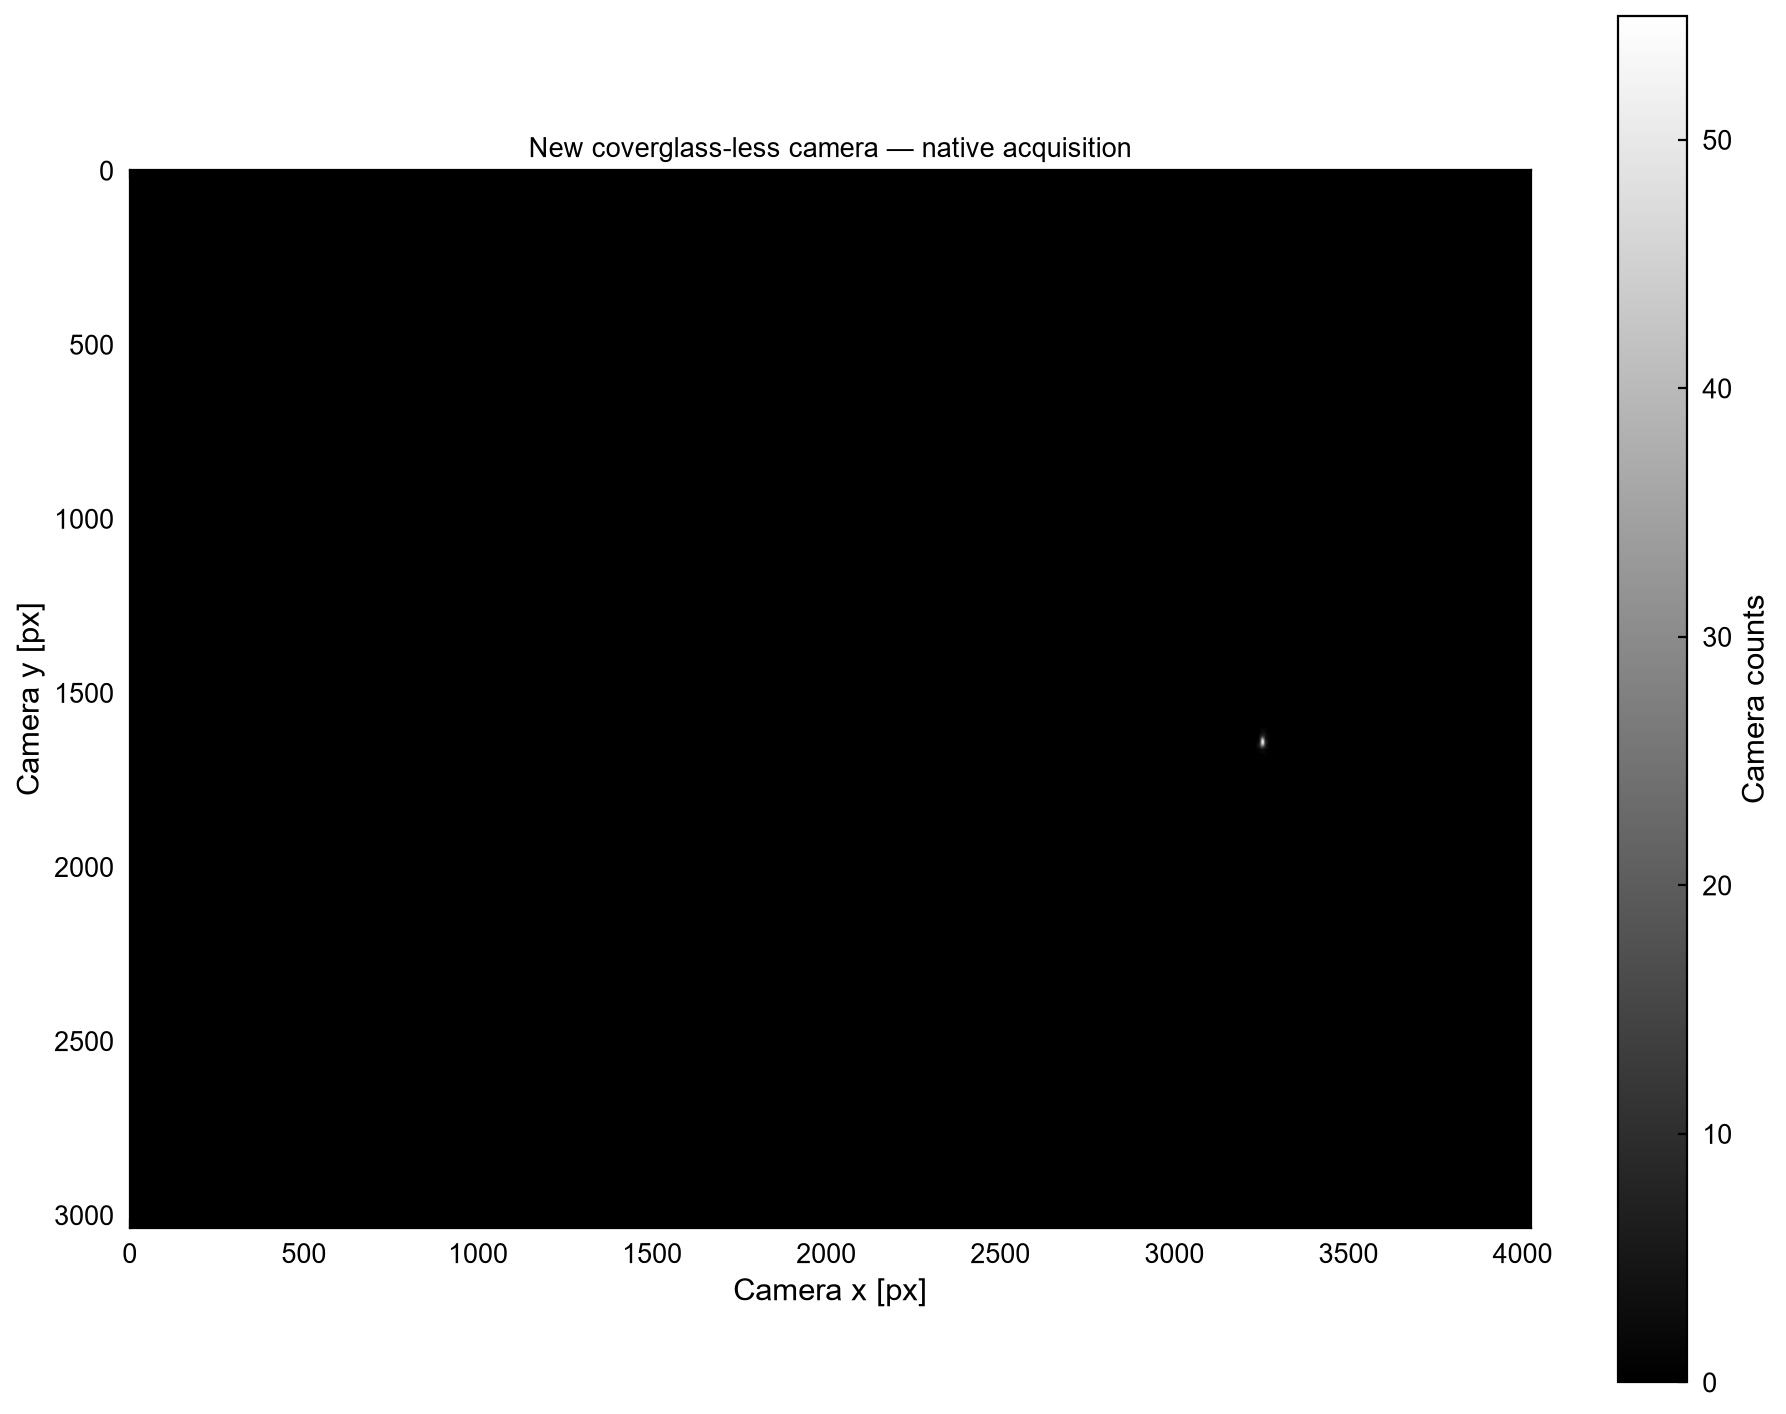

In [5]:
# ============================================================
# CELL 4 — Test native camera image acquisition
# ============================================================

from vmbpy import VmbSystem, FrameStatus
import time
import numpy as np
import matplotlib.pyplot as plt

CAMERA_ID = "DEV_1AB22C0E3243"

EXPOSURE_US = 30.0

print("Starting camera acquisition test...", flush=True)

t0 = time.perf_counter()

with VmbSystem.get_instance() as vmb:

    camera = vmb.get_camera_by_id(CAMERA_ID)

    with camera:

        print("Camera opened.", flush=True)

        # ----------------------------------------------------
        # Configure camera
        # ----------------------------------------------------

        camera.TriggerMode.set("Off")
        camera.ExposureAuto.set("Off")

        exposure_min, exposure_max = camera.ExposureTime.get_range()

        print(
            "Allowed exposure range [us]:",
            exposure_min, exposure_max,
            flush=True
        )

        exposure = float(np.clip(
            EXPOSURE_US,
            exposure_min,
            exposure_max
        ))

        camera.ExposureTime.set(exposure)

        print(
            "Actual exposure [us]:",
            camera.ExposureTime.get(),
            flush=True
        )

        print(
            "Pixel format:",
            camera.get_pixel_format(),
            flush=True
        )

        # ----------------------------------------------------
        # Acquire a single image
        # ----------------------------------------------------

        print("\nAcquiring image...", flush=True)

        t_acq = time.perf_counter()

        frame = camera.get_frame(timeout_ms=3000)

        print(
            f"Image acquired in "
            f"{time.perf_counter() - t_acq:.3f} s",
            flush=True
        )

        print("Frame status:", frame.get_status())

        if frame.get_status() != FrameStatus.Complete:
            raise RuntimeError("Incomplete camera frame")

        img_native = frame.as_numpy_ndarray().squeeze().copy()

    print("Camera connection closed.", flush=True)


# ------------------------------------------------------------
# Image diagnostics
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("IMAGE DIAGNOSTICS")
print("=" * 50)

print("Image shape:", img_native.shape)
print("Data type:", img_native.dtype)

print("Minimum counts:", img_native.min())
print("Maximum counts:", img_native.max())
print("Mean counts:", img_native.mean())

print(
    "Saturated pixels:",
    np.count_nonzero(img_native == 255)
)

print(
    f"Total execution time: "
    f"{time.perf_counter() - t0:.2f} s"
)


# ------------------------------------------------------------
# Display image
# ------------------------------------------------------------

plt.figure(figsize=(12, 9))

plt.imshow(
    img_native,
    cmap="gray",
    origin="upper",
    vmin=0,
    vmax=max(1, img_native.max())
)

plt.colorbar(label="Camera counts")

plt.xlabel("Camera x [px]")
plt.ylabel("Camera y [px]")

plt.title("New coverglass-less camera — native acquisition")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 6 — Custom Vimba X camera adapter for slmsuite
# Allied Vision Alvium 1800 U-1240m
# ============================================================

import numpy as np
import time

from contextlib import ExitStack
from vmbpy import VmbSystem, FrameStatus

from slmsuite.hardware.cameras.camera import Camera
from slmsuite.hardware.cameras.alliedvision import AlliedVision


class YDFCAlliedVision(AlliedVision):

    def __init__(
        self,
        camera_id,
        pitch_um=(1.85, 1.85),
        verbose=True
    ):

        # Manage persistent Vimba and camera connections
        self._stack = ExitStack()

        try:

            # ------------------------------------------------
            # 1. Start Vimba
            # ------------------------------------------------

            print("Starting Vimba X...", flush=True)

            self.sdk_handle = self._stack.enter_context(
                VmbSystem.get_instance()
            )

            # ------------------------------------------------
            # 2. Open the physical camera
            # ------------------------------------------------

            print("Opening camera...", flush=True)

            self.cam = self._stack.enter_context(
                self.sdk_handle.get_camera_by_id(camera_id)
            )

            print(
                "Camera opened:",
                self.cam.get_model(),
                flush=True
            )

            # ------------------------------------------------
            # 3. Minimal, verified camera configuration
            # ------------------------------------------------

            self.cam.TriggerMode.set("Off")
            self.cam.ExposureAuto.set("Off")

            self._exposure_time_has_abs = False

            width = self.cam.Width.get()
            height = self.cam.Height.get()

            pixel_format = self.cam.get_pixel_format()

            print("Resolution:", width, height, flush=True)
            print("Pixel format:", pixel_format, flush=True)

            if str(pixel_format) != "Mono8":
                raise RuntimeError(
                    f"Expected Mono8, found {pixel_format}"
                )

            # Read the actual allowed exposure range
            exp_min_us, exp_max_us = (
                self.cam.ExposureTime.get_range()
            )

            self.exposure_range_us = (
                exp_min_us,
                exp_max_us
            )

            # ------------------------------------------------
            # 4. Initialize slmsuite BASE camera class
            #
            # Deliberately bypass AlliedVision.__init__()
            # ------------------------------------------------

            print(
                "Initializing slmsuite base Camera...",
                flush=True
            )

            Camera.__init__(
                self,
                resolution=(width, height),
                bitdepth=8,
                pitch_um=pitch_um,
                name=self.cam.get_serial(),
                exposure_bounds_s=(
                    exp_min_us * 1e-6,
                    exp_max_us * 1e-6
                ),
                capture_attempts=5,
                averaging=None,
                hdr=None,
                rot="0",
                fliplr=False,
                flipud=False,
            )

            print(
                "Base Camera initialized successfully.",
                flush=True
            )

        except BaseException:

            self._stack.close()
            raise


    # ========================================================
    # Exposure control
    # ========================================================

    def _get_exposure_hw(self):

        return float(
            self.cam.ExposureTime.get()
        ) * 1e-6


    def _set_exposure_hw(self, exposure_s):

        exposure_us = float(exposure_s * 1e6)

        exp_min, exp_max = self.exposure_range_us

        exposure_us = float(
            np.clip(exposure_us, exp_min, exp_max)
        )

        self.cam.ExposureTime.set(exposure_us)


    # ========================================================
    # Image acquisition
    # ========================================================

    def _get_image_hw(self, timeout_s):

        timeout_ms = max(
            1,
            int(np.ceil(timeout_s * 1000))
        )

        frame = self.cam.get_frame(
            timeout_ms=timeout_ms
        )

        if frame.get_status() != FrameStatus.Complete:

            raise RuntimeError(
                f"Incomplete frame: {frame.get_status()}"
            )

        img = (
            frame.as_numpy_ndarray()
            .squeeze()
            .copy()
        )

        return img


    # ========================================================
    # Use base-class fallback for frame averaging
    # ========================================================

    def _get_images_hw(self, *args, **kwargs):

        raise NotImplementedError


    # ========================================================
    # Window of interest
    #
    # For now, retain the full native sensor frame.
    # ========================================================

    def set_woi(self, woi=None):

        if woi is not None:

            if tuple(woi) != tuple(self.woi):

                raise NotImplementedError(
                    "Hardware ROI is not implemented "
                    "in this adapter."
                )

        return self.woi


    # ========================================================
    # Close camera and Vimba connections
    # ========================================================

    def close(self):

        self._stack.close()


# ============================================================
# INITIALIZE THE NEW CAMERA
# ============================================================

print("\n" + "=" * 60)
print("INITIALIZING YDFC CAMERA")
print("=" * 60)

t0 = time.perf_counter()

cam = YDFCAlliedVision(
    camera_id="DEV_1AB22C0E3243",
    pitch_um=(1.85, 1.85),
)

print(
    f"\nCamera initialized in "
    f"{time.perf_counter() - t0:.2f} s"
)

print("\nCamera shape:", cam.shape)
print("Camera bitdepth:", cam.bitdepth)
print("Camera pixel pitch [um]:", cam.pitch_um)
print("Exposure [us]:", cam.get_exposure() * 1e6)


# ============================================================
# TEST SLMSUITE IMAGE ACQUISITION
# ============================================================

print("\nTesting slmsuite image acquisition...", flush=True)

t0 = time.perf_counter()

img_test = cam.get_image(
    timeout_s=3,
    averaging=False,
    hdr=False,
)

print(
    f"Image acquired in "
    f"{time.perf_counter() - t0:.3f} s"
)

print("Image shape:", img_test.shape)
print("Image dtype:", img_test.dtype)
print("Maximum counts:", img_test.max())

print(
    "Saturated pixels:",
    np.count_nonzero(img_test == 255)
)

print("\nCamera adapter working successfully!")


INITIALIZING YDFC CAMERA
Starting Vimba X...
Opening camera...
Camera opened: 1800 U-1240m
Resolution: 4024 3036
Pixel format: Mono8
Initializing slmsuite base Camera...
Base Camera initialized successfully.

Camera initialized in 2.61 s

Camera shape: (3036, 4024)
Camera bitdepth: 8
Camera pixel pitch [um]: [1.85 1.85]
Exposure [us]: 22.208

Testing slmsuite image acquisition...


c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\hardware\cameras\camera.py:444: UserWarning: '0JXVN' _get_image_hw() failed 1 times before quitting.
  warnings.warn(f"'{self.name}' _get_image_hw() failed {failures} times before quitting.")


Image acquired in 0.306 s
Image shape: (3036, 4024)
Image dtype: uint8
Maximum counts: 55
Saturated pixels: 0

Camera adapter working successfully!


Fourier calibration file found.
Fourier calibration restored!

Saved calibration:
{'M': array([[-164737.74610674,   -2021.13054946],
       [  -2061.02391279,  162379.33106457]]), '__meta__': {'__class__': '<slmsuite.hardware.cameraslms.FourierSLM object at 0x0000019E272C7200>', 'cam': {'__class__': '<__main__.YDFCAlliedVision object at 0x0000019E7F4CC680>', 'averaging': np.False_, 'bitdepth': np.int64(8), 'bitresolution': np.int64(256), 'default_shape': array([3036, 4024]), 'exposure_bounds_s': array([2.22080000e-05, 9.99998749e+00]), 'exposure_s': np.float64(0.000747208), 'hdr': np.False_, 'name': '0JXVN', 'pitch_um': array([1.85, 1.85]), 'shape': array([3036, 4024]), 'woi': array([   0, 4024,    0, 3036])}, 'mag': np.float64(1.0), 'name': '0JXVN-Meadowlark HDMI', 'slm': {'__class__': '<slmsuite.hardware.slms.meadowlark.Meadowlark object at 0x0000019E7FA704D0>', 'bitdepth': np.int64(8), 'bitresolution': np.int64(256), 'name': 'Meadowlark HDMI', 'phase_scaling': np.float64(1.0), 'pitc

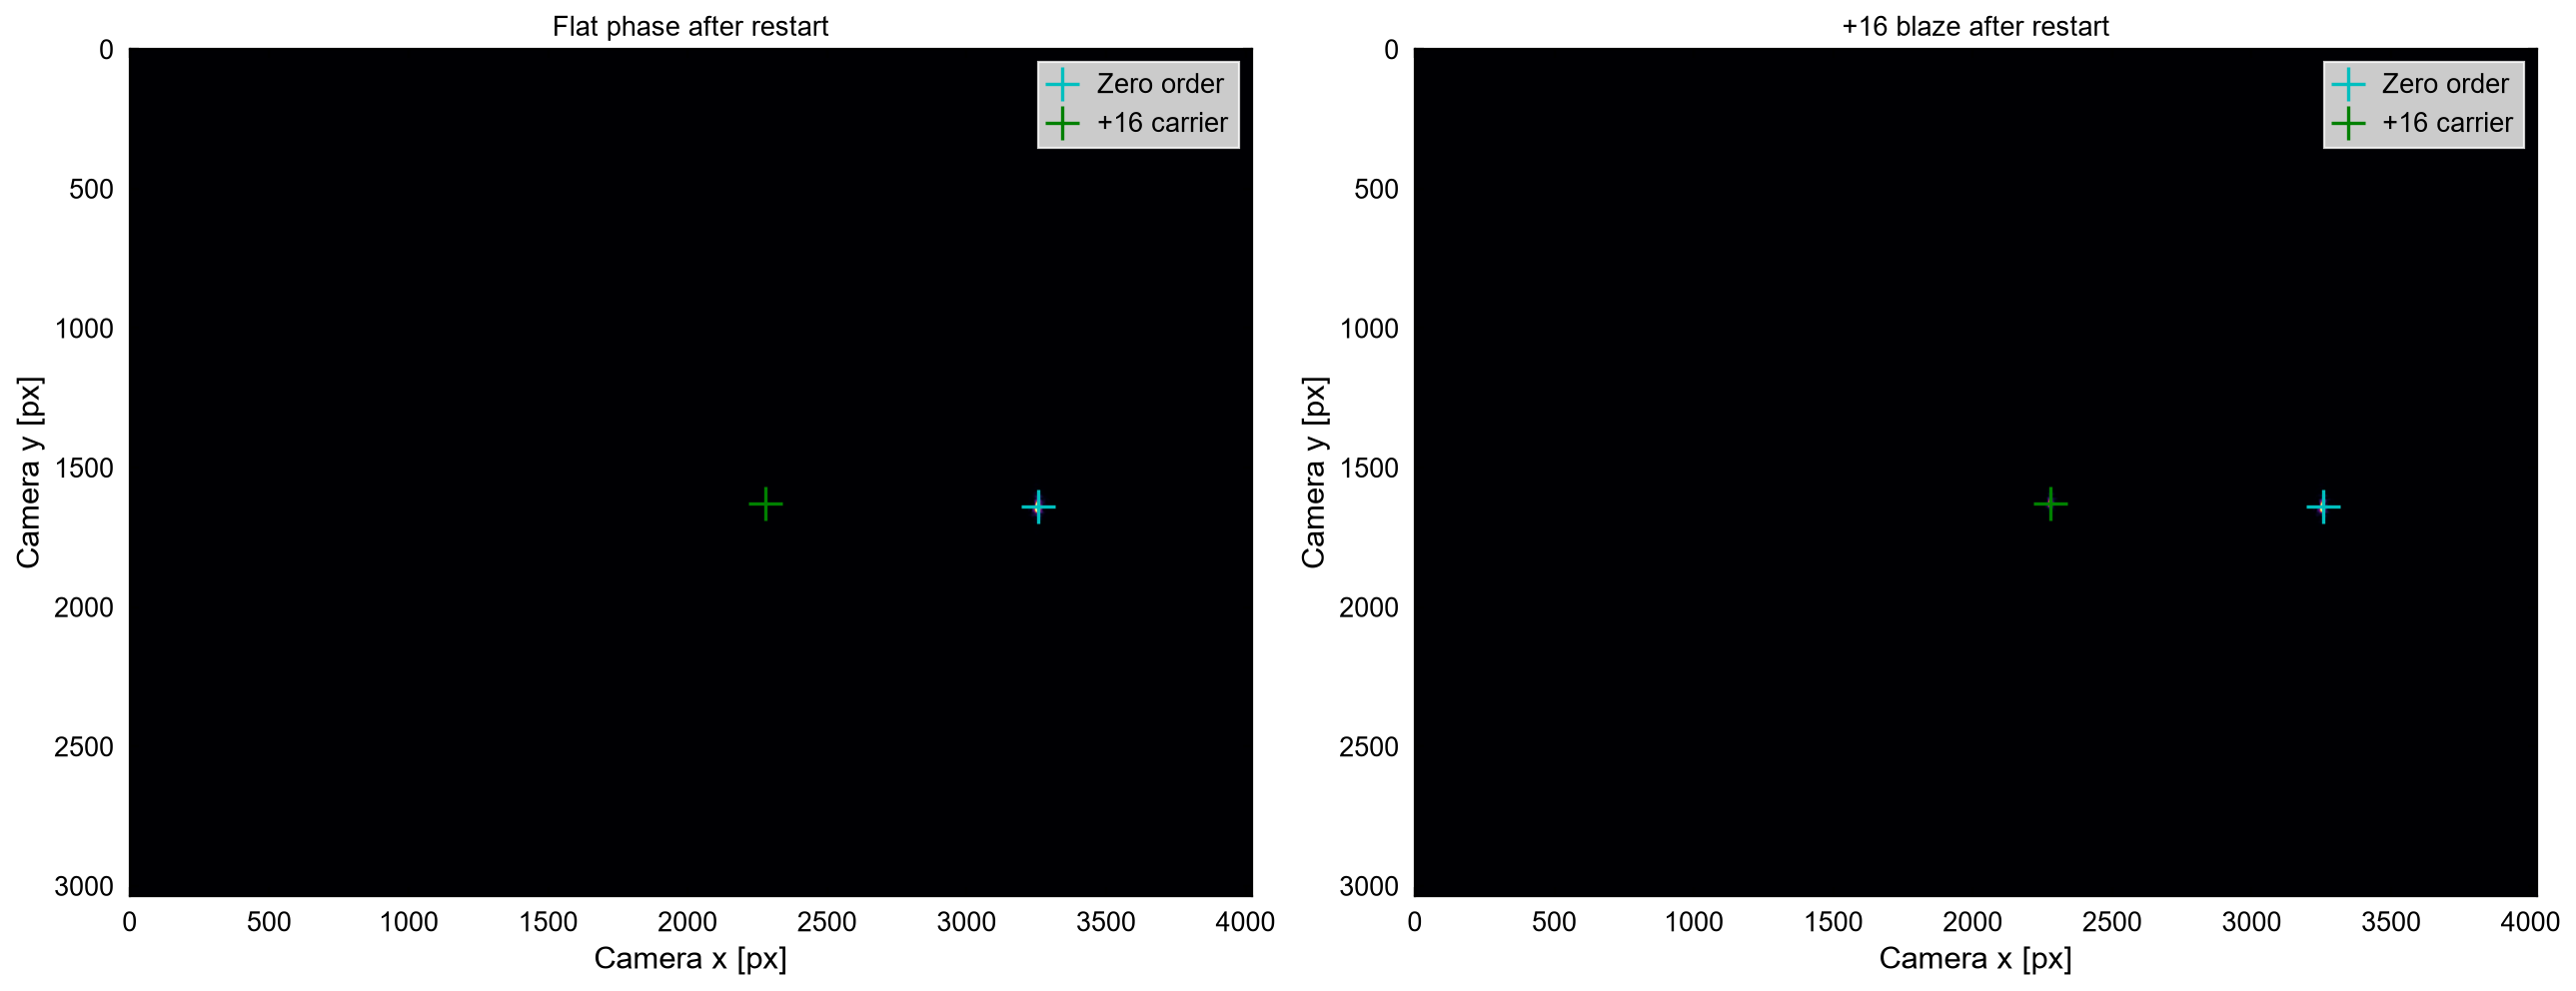


SLM diffraction recovered, but the carrier is saturated.


In [10]:
# ============================================================
# CELL 12 — Restore calibration after SLM restart
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import time

from slmsuite.hardware.cameraslms import FourierSLM
from slmsuite.holography import toolbox


# ------------------------------------------------------------
# 1. Restore the EXISTING calibration directory
#
# Cell 1 may have created a new directory after the restart.
# We want to continue using the previous calibration.
# ------------------------------------------------------------

CAL_DIR = Path(
    r"c:\Users\admin\Desktop\Projects\SLM\SLM tests"
    r"\Scripts\Main breadboard"
    r"\YDFC_calibration_20261112_184714"
)

FOURIER_FILE = (
    CAL_DIR /
    "YDFC_fourier_pre_wavefront_00000.h5"
)

assert FOURIER_FILE.is_file(), (
    f"Calibration file not found:\n{FOURIER_FILE}"
)

print("Fourier calibration file found.")


# ------------------------------------------------------------
# 2. Create FourierSLM and load saved calibration
# ------------------------------------------------------------

fs = FourierSLM(cam, slm)

fs.load_calibration(
    "fourier",
    file_path=str(FOURIER_FILE)
)

print("Fourier calibration restored!")

print("\nSaved calibration:")
print(fs.calibrations["fourier"])


# ------------------------------------------------------------
# 3. Ensure wavefront correction is OFF
# ------------------------------------------------------------

slm.source.pop("phase", None)
slm.source.pop("amplitude", None)

print("\nSLM source keys:", list(slm.source.keys()))


# ------------------------------------------------------------
# 4. Reconstruct +16 carrier
# ------------------------------------------------------------

CARRIER_PERIOD_PX = 16

KXY_CARRIER = np.array([
    1.0 / (
        CARRIER_PERIOD_PX * slm.pitch[0]
    ),
    0.0
])

IJ_ZERO = np.asarray(
    fs.kxyslm_to_ijcam([0, 0])
).ravel()

IJ_CARRIER = np.asarray(
    fs.kxyslm_to_ijcam(KXY_CARRIER)
).ravel()

print("\nPredicted zero order:", IJ_ZERO)
print("Predicted carrier:", IJ_CARRIER)


# ------------------------------------------------------------
# 5. Set camera to minimum exposure
# ------------------------------------------------------------

cam.set_exposure(
    cam.exposure_range_us[0] * 1e-6
)

# Maintain fixed gain for comparison

cam.cam.GainAuto.set("Off")
cam.cam.Gain.set(0.0)

print("\nExposure [us]:",
      cam.get_exposure() * 1e6)

print("Camera gain:", cam.cam.Gain.get())


# ------------------------------------------------------------
# 6. Display flat phase
# ------------------------------------------------------------

slm.set_phase(
    np.zeros(slm.shape),
    phase_correct=False,
    settle=True,
    execute=True
)

time.sleep(0.5)

cam.flush(timeout_s=3)

img_zero_restart = cam.get_image(
    timeout_s=3
).copy()


# ------------------------------------------------------------
# 7. Display +16-pixel blaze
# ------------------------------------------------------------

phase_carrier = toolbox.phase.blaze(
    slm,
    vector=KXY_CARRIER
)

slm.set_phase(
    phase_carrier,
    phase_correct=False,
    settle=True,
    execute=True
)

time.sleep(0.5)

cam.flush(timeout_s=3)

img_carrier_restart = cam.get_image(
    timeout_s=3
).copy()


# ------------------------------------------------------------
# 8. Check diffraction signal
# ------------------------------------------------------------

def local_peak(image, center, radius=60):

    xc, yc = np.round(center).astype(int)

    roi = image[
        yc-radius:yc+radius+1,
        xc-radius:xc+radius+1
    ]

    return roi.max()


zero_peak_flat = local_peak(
    img_zero_restart,
    IJ_ZERO
)

carrier_peak_flat = local_peak(
    img_zero_restart,
    IJ_CARRIER
)

zero_peak_blaze = local_peak(
    img_carrier_restart,
    IJ_ZERO
)

carrier_peak_blaze = local_peak(
    img_carrier_restart,
    IJ_CARRIER
)


print("\n" + "=" * 60)
print("SLM RESTART VERIFICATION")
print("=" * 60)

print("\nFlat phase:")
print("Zero-order peak:", zero_peak_flat)
print("Carrier peak:", carrier_peak_flat)

print("\n+16 blaze:")
print("Zero-order peak:", zero_peak_blaze)
print("Carrier peak:", carrier_peak_blaze)

print("\nSaturated pixels:")
print(
    "Flat phase:",
    np.count_nonzero(img_zero_restart == 255)
)

print(
    "Carrier:",
    np.count_nonzero(img_carrier_restart == 255)
)


# ------------------------------------------------------------
# 9. Plot full camera images
# ------------------------------------------------------------

fig, axs = plt.subplots(
    1, 2,
    figsize=(16, 7),
    constrained_layout=True
)

for ax, img, title in [
    (
        axs[0],
        img_zero_restart,
        "Flat phase after restart"
    ),
    (
        axs[1],
        img_carrier_restart,
        "+16 blaze after restart"
    )
]:

    ax.imshow(
        img,
        cmap="inferno",
        origin="upper",
        vmin=0,
        vmax=max(1, img.max())
    )

    ax.plot(
        *IJ_ZERO,
        "c+",
        markersize=15,
        label="Zero order"
    )

    ax.plot(
        *IJ_CARRIER,
        "g+",
        markersize=15,
        label="+16 carrier"
    )

    ax.set_title(title)
    ax.set_xlabel("Camera x [px]")
    ax.set_ylabel("Camera y [px]")
    ax.legend()

plt.show()


# ------------------------------------------------------------
# 10. Final check
# ------------------------------------------------------------

if carrier_peak_blaze < 20:

    print(
        "\nWARNING: Carrier is still weak or absent."
    )

    print(
        "Test the SLM directly using Meadowlark "
        "Blink software."
    )

elif carrier_peak_blaze >= 255:

    print(
        "\nSLM diffraction recovered, "
        "but the carrier is saturated."
    )

else:

    print(
        "\nSUCCESS: SLM diffraction recovered!"
    )

    print(
        "Ready to resume wavefront calibration."
    )

Reference patch: (11, 7)
Test patch: (14, 7)
Calibration point: [2278.48820114 1628.21278263]
Field dump kxy: [0.         0.01186406]

Exposure: 22.208 us
Phase 0.000 rad | ROI max = 0 | Full-frame saturation = 307
Phase 1.571 rad | ROI max = 0 | Full-frame saturation = 295
Phase 3.142 rad | ROI max = 0 | Full-frame saturation = 301
Phase 4.712 rad | ROI max = 0 | Full-frame saturation = 300

Central phase signals: [0. 0. 0. 0.]
Central modulation: 0.0
Maximum spatial modulation: 0.0
Maximum modulation position: (np.int64(2028), np.int64(1378))
ROI saturation: False

Exposure: 203.458 us
Phase 0.000 rad | ROI max = 0 | Full-frame saturation = 1057
Phase 1.571 rad | ROI max = 1 | Full-frame saturation = 1042
Phase 3.142 rad | ROI max = 0 | Full-frame saturation = 1061
Phase 4.712 rad | ROI max = 0 | Full-frame saturation = 1079

Central phase signals: [0. 0. 0. 0.]
Central modulation: 0.0
Maximum spatial modulation: 0.019895067570382008
Maximum modulation position: (np.int64(2200), np.i

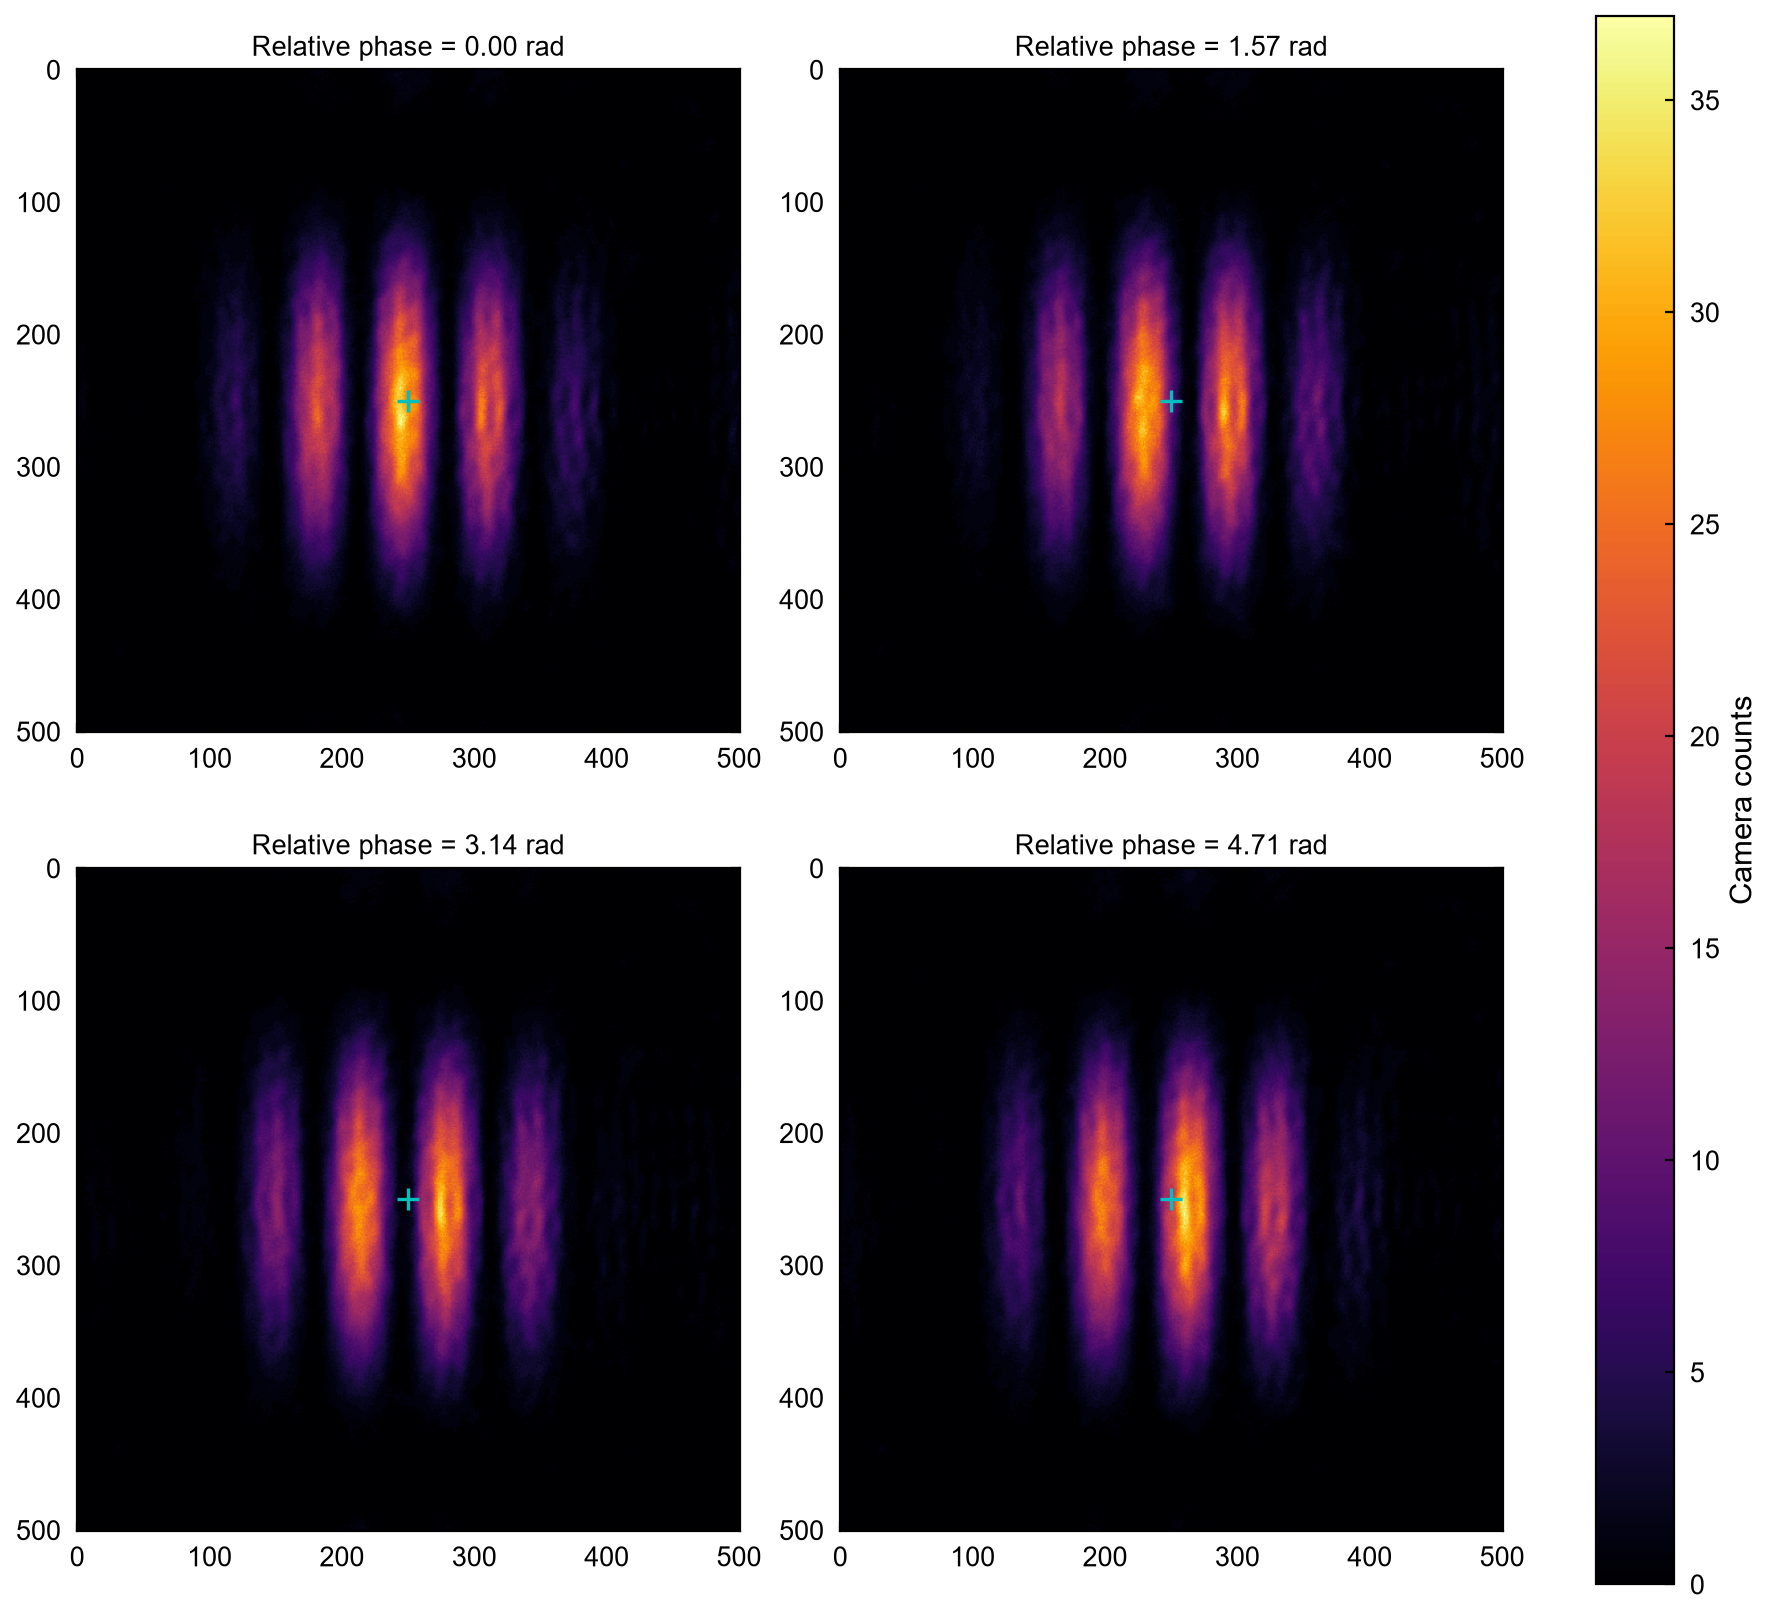

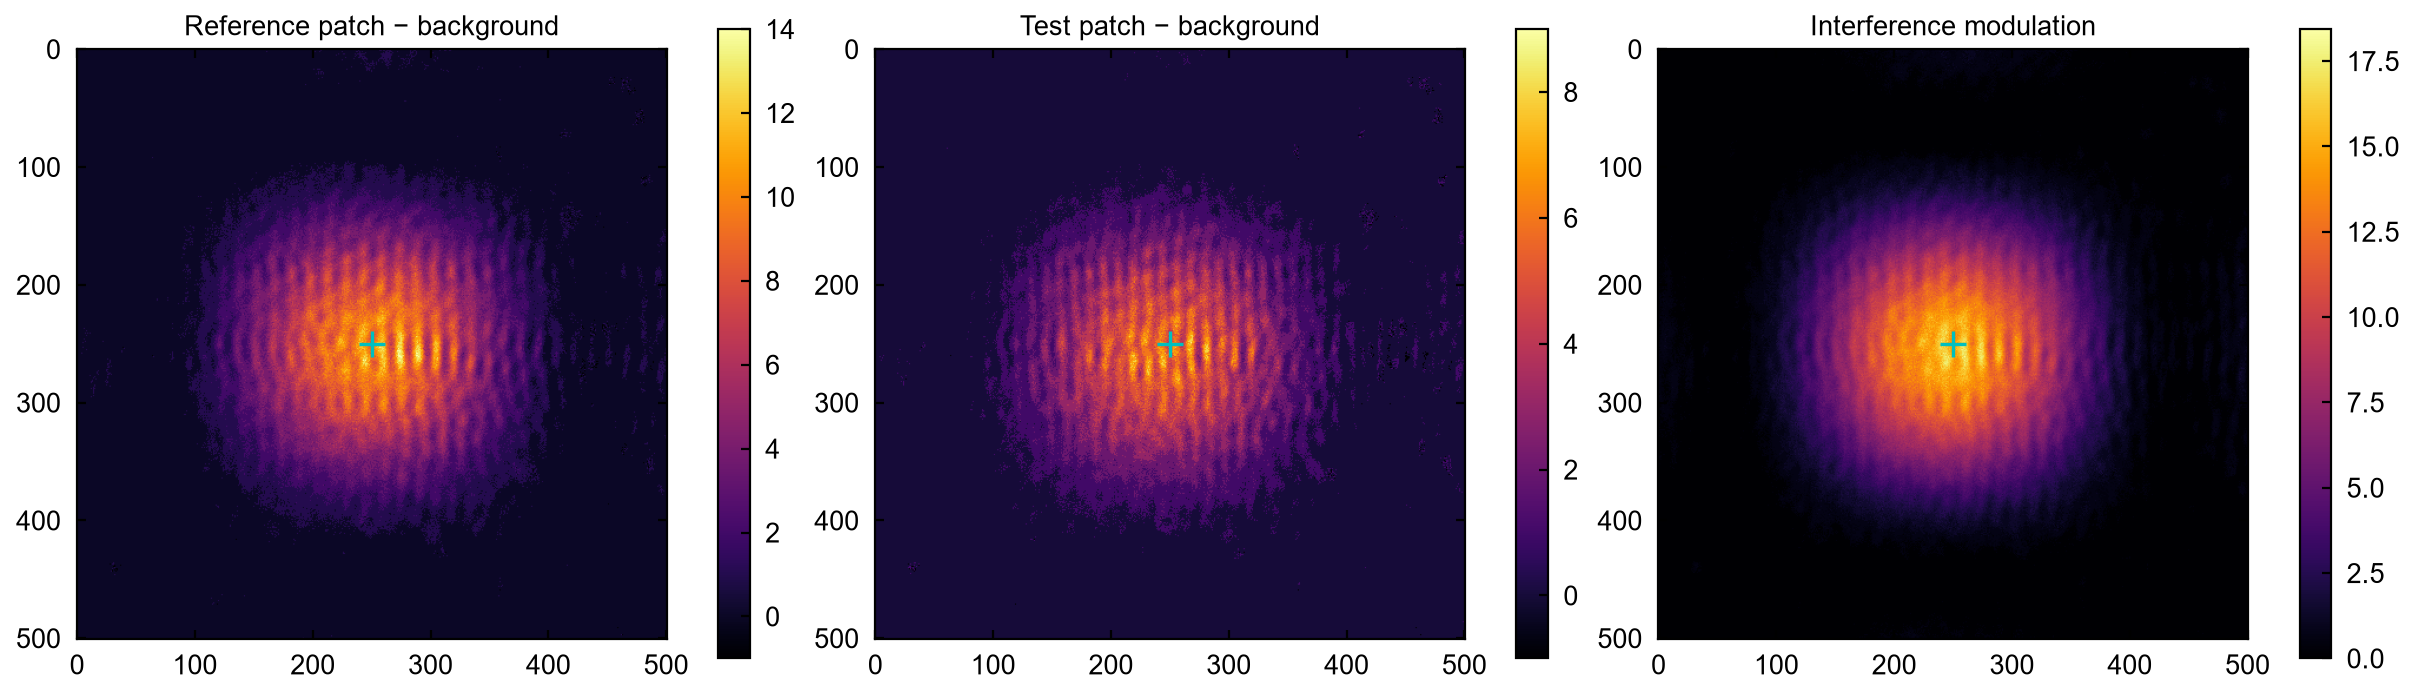

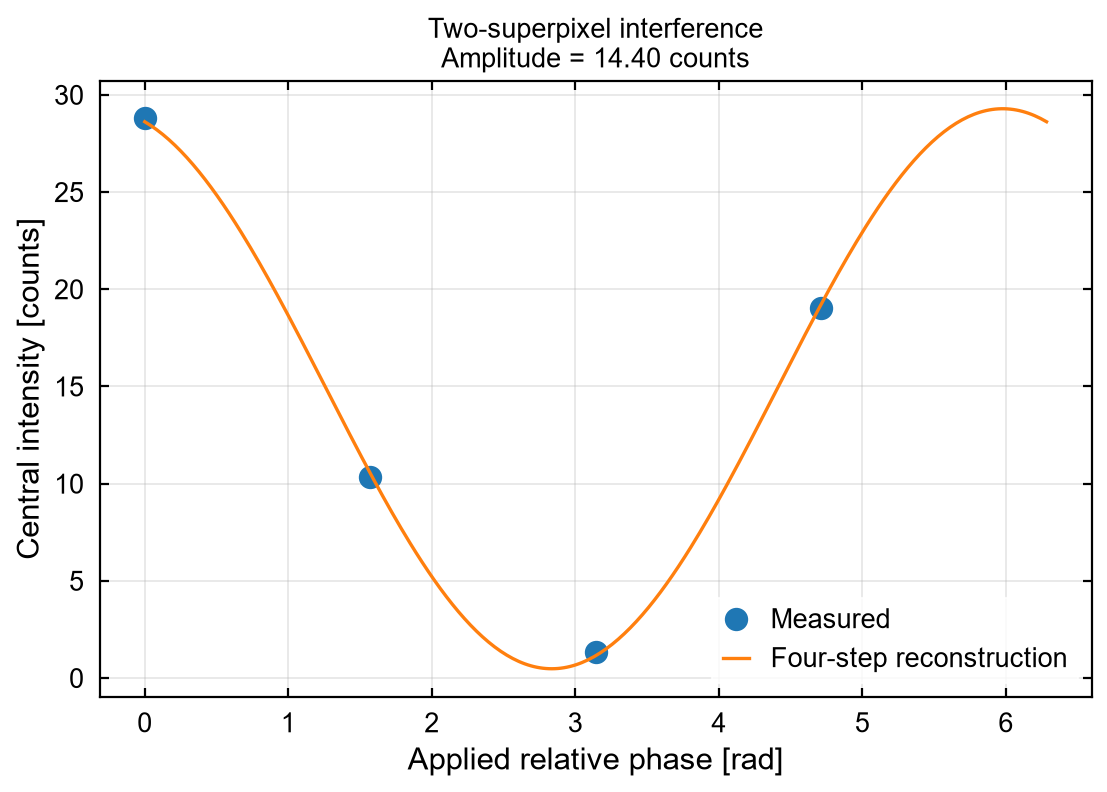


CELL 13 COMPLETED SUCCESSFULLY!
SLM left displaying the field-dump pattern.


In [11]:
# ============================================================
# CELL 13 — Two-superpixel interference after SLM restart
# YDFC | Adaptive exposure | Wavefront correction OFF
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import time

from scipy.ndimage import gaussian_filter
from slmsuite.holography import toolbox


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SP_SIZE = 80

REF_SP = (11, 7)
TEST_SP = (14, 7)

EXPOSURES_US = [
    22.208,
    200,
    1000,
    5000,
    20000,
    50000
]

PHASE_STEPS = np.arange(4) * np.pi / 2

TARGET_MODULATION = 8.0  # camera counts

# Calibration point: +16 carrier

WF_CAL_POINT = np.asarray(
    fs.kxyslm_to_ijcam(KXY_CARRIER)
).ravel()

xc_wf, yc_wf = np.round(
    WF_CAL_POINT
).astype(int)

# Dump direction: vertical 8-pixel blaze

FIELD_POINT_KXY = np.array([
    0.0,
    1.0 / (8 * slm.pitch[1])
])

print("Reference patch:", REF_SP)
print("Test patch:", TEST_SP)
print("Calibration point:", WF_CAL_POINT)
print("Field dump kxy:", FIELD_POINT_KXY)


# ------------------------------------------------------------
# 2. Generate phase patterns
# ------------------------------------------------------------

phase_signal = toolbox.phase.blaze(
    slm,
    vector=KXY_CARRIER
)

phase_dump = toolbox.phase.blaze(
    slm,
    vector=FIELD_POINT_KXY
)


def sp_slice(sp):

    sx, sy = sp

    return (
        slice(sy * SP_SIZE, (sy + 1) * SP_SIZE),
        slice(sx * SP_SIZE, (sx + 1) * SP_SIZE)
    )


ref_slice = sp_slice(REF_SP)
test_slice = sp_slice(TEST_SP)


def make_phase(
    reference_on=False,
    test_on=False,
    test_phase=0.0
):

    phase = phase_dump.copy()

    if reference_on:

        phase[ref_slice] = phase_signal[ref_slice]

    if test_on:

        phase[test_slice] = (
            phase_signal[test_slice] + test_phase
        )

    return np.mod(phase, 2 * np.pi)


# ------------------------------------------------------------
# 3. Define camera measurement regions
# ------------------------------------------------------------

# Large ROI for diffraction envelope

R = 250

camera_slice = (
    slice(yc_wf - R, yc_wf + R + 1),
    slice(xc_wf - R, xc_wf + R + 1)
)

# Small central ROI for phase measurement

r = 4

center_slice = (
    slice(R - r, R + r + 1),
    slice(R - r, R + r + 1)
)


# ------------------------------------------------------------
# 4. Helper function for acquisition
# ------------------------------------------------------------

def acquire_pattern(phase):

    slm.set_phase(
        phase,
        phase_correct=False,
        settle=True,
        execute=True
    )

    img = cam.get_image(
        timeout_s=3,
        averaging=False,
        hdr=False
    )

    crop = img[camera_slice].astype(float).copy()

    full_saturation = np.count_nonzero(
        img == 255
    )

    return crop, full_saturation


# ------------------------------------------------------------
# 5. Adaptive exposure scan
# ------------------------------------------------------------

results = []

t0 = time.perf_counter()

try:

    # Start with dump pattern, not full-aperture carrier

    cam.set_exposure(
        cam.exposure_range_us[0] * 1e-6
    )

    slm.set_phase(
        phase_dump,
        phase_correct=False,
        settle=True,
        execute=True
    )

    for exposure_us in EXPOSURES_US:

        print("\n" + "=" * 55)

        cam.set_exposure(
            exposure_us * 1e-6
        )

        actual_exposure_us = (
            cam.get_exposure() * 1e6
        )

        print(
            f"Exposure: {actual_exposure_us:.3f} us",
            flush=True
        )

        # Discard first frame after exposure change

        cam.get_image(
            timeout_s=3,
            averaging=False,
            hdr=False
        )

        # ----------------------------------------------------
        # Acquire four relative phases
        # ----------------------------------------------------

        images = []
        full_sat_counts = []

        for phi in PHASE_STEPS:

            pattern = make_phase(
                reference_on=True,
                test_on=True,
                test_phase=phi
            )

            crop, n_sat_full = acquire_pattern(
                pattern
            )

            images.append(crop)

            full_sat_counts.append(
                n_sat_full
            )

            print(
                f"Phase {phi:.3f} rad | "
                f"ROI max = {crop.max():.0f} | "
                f"Full-frame saturation = {n_sat_full}",
                flush=True
            )

        images = np.asarray(images)

        # ----------------------------------------------------
        # Four-step interferometry
        # ----------------------------------------------------

        I0, I90, I180, I270 = images

        mean_map = (
            I0 + I90 + I180 + I270
        ) / 4

        C_map = (I0 - I180) / 2

        S_map = (I90 - I270) / 2

        amplitude_map = np.hypot(
            C_map,
            S_map
        )

        phase_map = np.arctan2(
            -S_map,
            C_map
        )

        # Central phase-dependent signal

        center_values = np.array([
            image[center_slice].mean()
            for image in images
        ])

        C_center = (
            center_values[0]
            - center_values[2]
        ) / 2

        S_center = (
            center_values[1]
            - center_values[3]
        ) / 2

        A_center = np.hypot(
            C_center,
            S_center
        )

        delta_center = np.arctan2(
            -S_center,
            C_center
        )

        # Find strongest spatial modulation,
        # suppressing isolated noisy pixels

        amplitude_smooth = gaussian_filter(
            amplitude_map,
            sigma=2
        )

        peak_modulation = amplitude_smooth.max()

        yp, xp = np.unravel_index(
            np.argmax(amplitude_smooth),
            amplitude_smooth.shape
        )

        peak_position = (
            xc_wf - R + xp,
            yc_wf - R + yp
        )

        saturated = np.any(images >= 255)

        print("\nCentral phase signals:",
              np.round(center_values, 2))

        print("Central modulation:", A_center)

        print("Maximum spatial modulation:",
              peak_modulation)

        print("Maximum modulation position:",
              peak_position)

        print("ROI saturation:", saturated)

        # ----------------------------------------------------
        # Stop if the measurement ROI saturates
        # ----------------------------------------------------

        if saturated:

            print(
                "Measurement ROI saturated. "
                "Stopping exposure increase."
            )

            break

        results.append({

            "exposure_us": actual_exposure_us,

            "images": images.copy(),

            "center_values": center_values.copy(),

            "mean_map": mean_map.copy(),

            "amplitude_map": amplitude_map.copy(),

            "phase_map": phase_map.copy(),

            "A_center": A_center,

            "delta_center": delta_center,

            "peak_modulation": peak_modulation,

            "peak_position": peak_position,

            "full_saturation": full_sat_counts

        })

        if A_center >= TARGET_MODULATION:

            print(
                "\nSufficient interference signal obtained!"
            )

            break

        if images.max() >= 200:

            print(
                "\nApproaching saturation. "
                "Stopping exposure increase."
            )

            break


    # --------------------------------------------------------
    # 6. Select best unsaturated measurement
    # --------------------------------------------------------

    if len(results) == 0:

        raise RuntimeError(
            "No unsaturated measurement obtained. "
            "Reduce optical power."
        )

    best = max(
        results,
        key=lambda item: item["A_center"]
    )

    cam.set_exposure(
        best["exposure_us"] * 1e-6
    )

    print("\n" + "=" * 55)

    print(
        "Selected exposure [us]:",
        best["exposure_us"]
    )

    # --------------------------------------------------------
    # 7. Measure the background and individual patches
    # --------------------------------------------------------

    bg_crop, _ = acquire_pattern(
        make_phase(False, False)
    )

    ref_crop, _ = acquire_pattern(
        make_phase(True, False)
    )

    test_crop, _ = acquire_pattern(
        make_phase(False, True)
    )


finally:

    # IMPORTANT:
    # Restore minimum exposure and leave the field dump ON.
    #
    # Do NOT restore full-aperture +16 carrier at the
    # increased laser power.

    cam.set_exposure(
        cam.exposure_range_us[0] * 1e-6
    )

    slm.set_phase(
        phase_dump,
        phase_correct=False,
        settle=True,
        execute=True
    )


# ------------------------------------------------------------
# 8. Calculate interference diagnostics
# ------------------------------------------------------------

I_bg = bg_crop[center_slice].mean()

I_ref = (
    ref_crop[center_slice].mean() - I_bg
)

I_test = (
    test_crop[center_slice].mean() - I_bg
)

B = best["center_values"].mean()

A = best["A_center"]

delta = best["delta_center"]

if B > I_bg:

    visibility = A / (B - I_bg)

else:

    visibility = np.nan


if I_ref > 0 and I_test > 0:

    visibility_ideal = (
        2 * np.sqrt(I_ref * I_test)
        / (I_ref + I_test)
    )

else:

    visibility_ideal = np.nan


print("\n" + "=" * 60)
print("INTERFERENCE TEST RESULTS")
print("=" * 60)

print("Exposure [us]:",
      best["exposure_us"])

print("Background:", I_bg)

print("Reference signal above background:",
      I_ref)

print("Test signal above background:",
      I_test)

print("\nCentral modulation amplitude:", A)

print("Measured visibility:", visibility)

print("Ideal visibility:", visibility_ideal)

print("Relative phase [rad]:", delta)

print("Peak spatial modulation:",
      best["peak_modulation"])

print("Peak modulation position:",
      best["peak_position"])

print("\nTotal elapsed time [s]:",
      time.perf_counter() - t0)


# ------------------------------------------------------------
# 9. Plot the four interference images
# ------------------------------------------------------------

fig, axs = plt.subplots(
    2, 2,
    figsize=(11, 10),
    constrained_layout=True
)

vmax = max(1, best["images"].max())

for ax, img, phi in zip(
    axs.ravel(),
    best["images"],
    PHASE_STEPS
):

    im = ax.imshow(
        img,
        cmap="inferno",
        vmin=0,
        vmax=vmax
    )

    ax.plot(
        R, R,
        "c+",
        markersize=10
    )

    ax.set_title(
        f"Relative phase = {phi:.2f} rad"
    )

fig.colorbar(
    im,
    ax=axs.ravel(),
    label="Camera counts"
)

plt.show()


# ------------------------------------------------------------
# 10. Plot individual patch signals
# ------------------------------------------------------------

fig, axs = plt.subplots(
    1, 3,
    figsize=(15, 5),
    constrained_layout=True
)

for ax, img, title in zip(

    axs,

    [
        ref_crop - bg_crop,
        test_crop - bg_crop,
        best["amplitude_map"]
    ],

    [
        "Reference patch − background",
        "Test patch − background",
        "Interference modulation"
    ]
):

    im = ax.imshow(
        img,
        cmap="inferno"
    )

    ax.plot(
        R, R,
        "c+",
        markersize=12
    )

    ax.set_title(title)

    fig.colorbar(
        im,
        ax=ax,
        shrink=0.8
    )

plt.show()


# ------------------------------------------------------------
# 11. Plot the phase-stepping result
# ------------------------------------------------------------

phi_fine = np.linspace(
    0,
    2 * np.pi,
    300
)

I_fit = (
    B
    + A * np.cos(phi_fine + delta)
)

plt.figure(figsize=(8, 5))

plt.plot(
    PHASE_STEPS,
    best["center_values"],
    "o",
    markersize=9,
    label="Measured"
)

plt.plot(
    phi_fine,
    I_fit,
    "-",
    label="Four-step reconstruction"
)

plt.xlabel("Applied relative phase [rad]")

plt.ylabel("Central intensity [counts]")

plt.title(
    f"Two-superpixel interference\n"
    f"Amplitude = {A:.2f} counts"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ------------------------------------------------------------
# 12. Save the diagnostic
# ------------------------------------------------------------

np.savez(
    CAL_DIR / "wavefront_interference_after_restart.npz",

    exposure_us=best["exposure_us"],

    reference_superpixel=REF_SP,
    test_superpixel=TEST_SP,

    phase_steps=PHASE_STEPS,

    center_values=best["center_values"],

    background=bg_crop,
    reference_image=ref_crop,
    test_image=test_crop,

    modulation_amplitude=A,

    relative_phase=delta,

    visibility=visibility,

    amplitude_map=best["amplitude_map"],

    phase_map=best["phase_map"],

    phase_images=best["images"]
)

print("\nCELL 13 COMPLETED SUCCESSFULLY!")
print("SLM left displaying the field-dump pattern.")

Zero-order position: [3255.7176591  1640.43884089]
Carrier position: [2278.48820114 1628.21278263]
Separation [px]: 977.3059347025454

Wavefront interference window [px]: [776 776]
Masked pixels: 196364
Mask overlap with interference window: 0

Actual exposure [us]: 19999.986

RAW IMAGE SATURATION ANALYSIS
Total saturated pixels: 11718
Saturated pixels inside zero-order mask: 11718
Saturated pixels outside zero-order mask: 0
Saturated pixels in wavefront window: 0
Fraction of saturation inside mask [%]: 100.0

MASKED IMAGE
Maximum intensity: 83
Remaining saturated pixels: 0
Wavefront interference window unchanged.


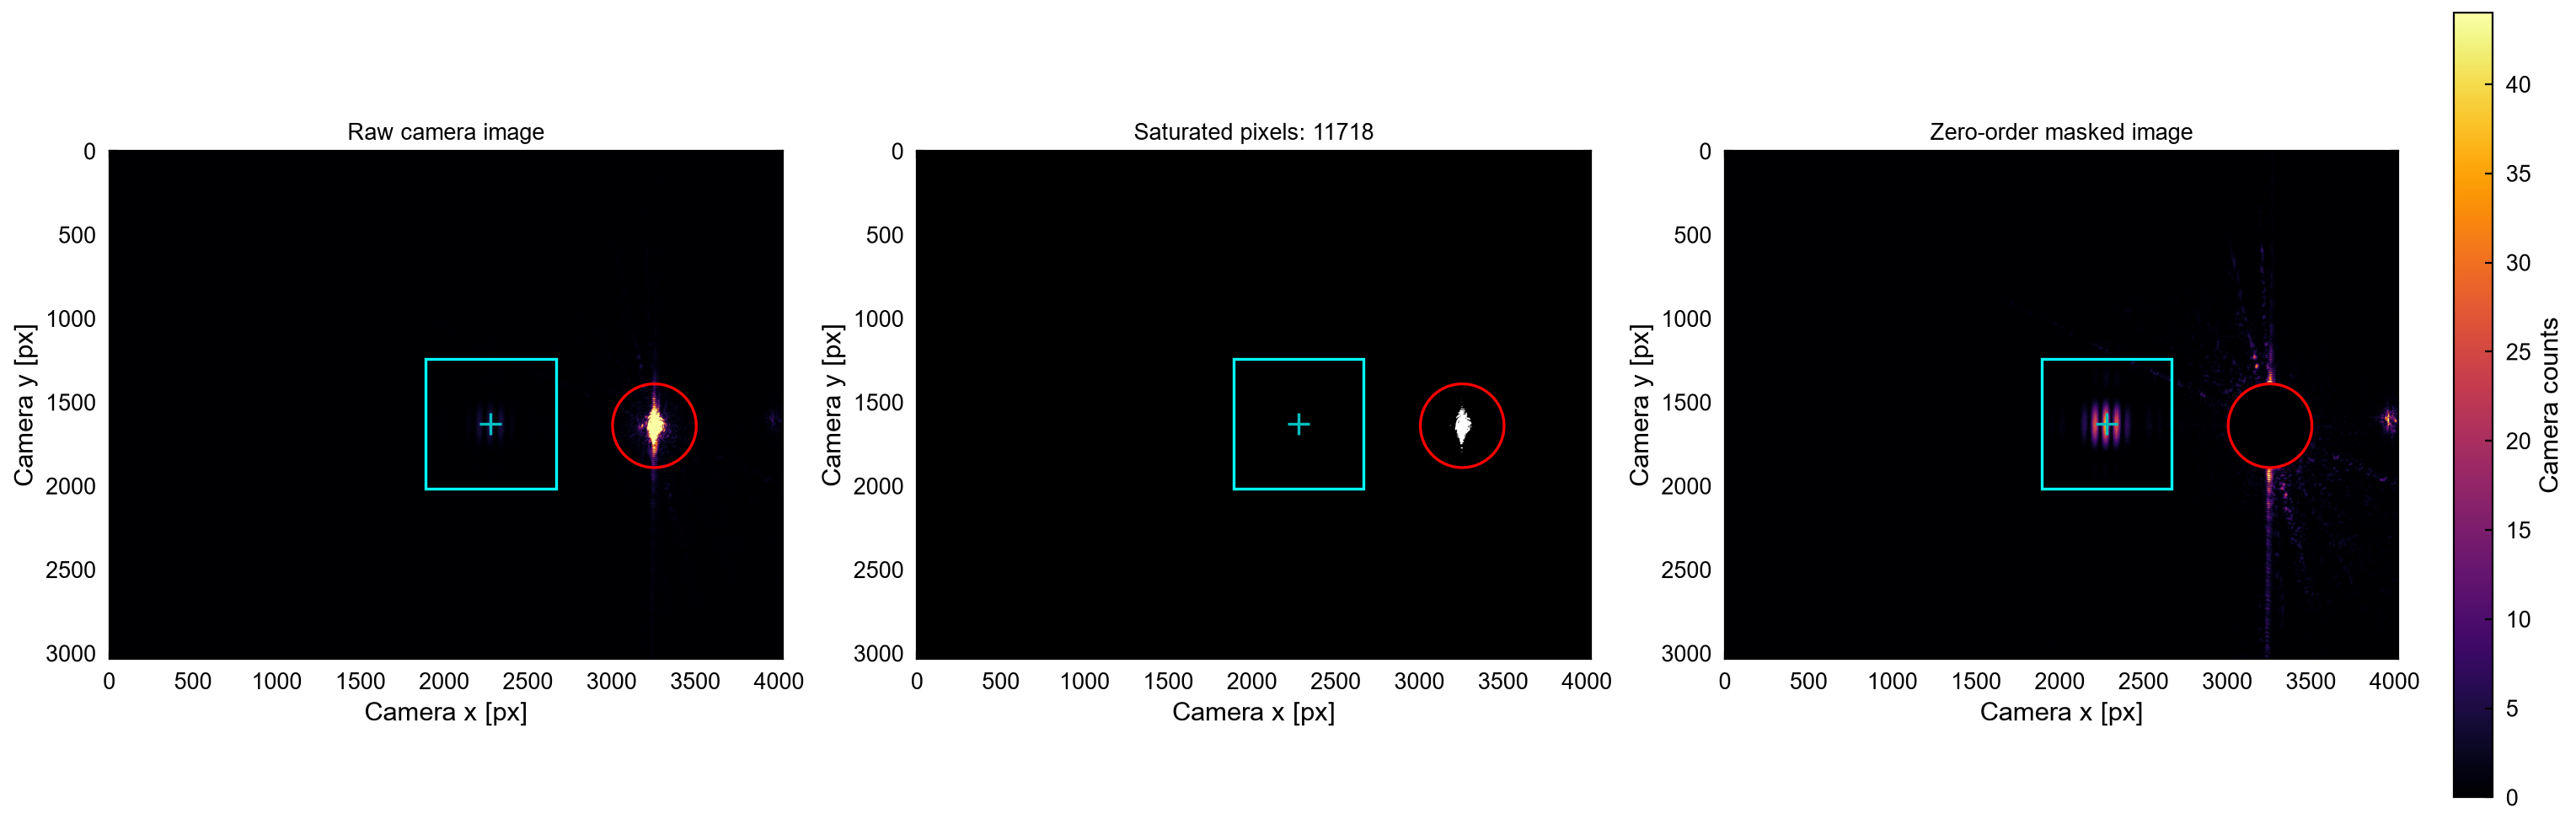


Zero-order masking diagnostic saved.
SUCCESS: Saturation is confined to the masked zero-order region.


c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\numpy\lib\_format_impl.py:393: UserWarning: metadata on a dtype is not saved to an npy/npz. Use another format (such as pickle) to store it.
  d['descr'] = dtype_to_descr(array.dtype)


In [12]:
# ============================================================
# CELL 14 — Computational zero-order masking
# YDFC | Preserve full camera coordinates
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Circle, Rectangle


# ------------------------------------------------------------
# 1. Calibration parameters
# ------------------------------------------------------------

SUPERPIXEL_SIZE = 80

ZERO_MASK_RADIUS = 250  # camera pixels

WF_EXPOSURE_US = 20_000

# Positions from existing Fourier calibration

IJ_ZERO = np.asarray(
    fs.kxyslm_to_ijcam([0, 0])
).ravel()

IJ_CARRIER = np.asarray(
    fs.kxyslm_to_ijcam(KXY_CARRIER)
).ravel()

x_zero, y_zero = IJ_ZERO
x_carrier, y_carrier = IJ_CARRIER

print("Zero-order position:", IJ_ZERO)
print("Carrier position:", IJ_CARRIER)

print(
    "Separation [px]:",
    np.linalg.norm(IJ_CARRIER - IJ_ZERO)
)


# ------------------------------------------------------------
# 2. Calculate actual slmsuite interference window
# ------------------------------------------------------------

wf_window = np.asarray(
    fs.wavefront_calibration_superpixel_window(
        SUPERPIXEL_SIZE
    )
).ravel()

if wf_window.size == 1:
    wf_window = np.repeat(wf_window, 2)

window_x, window_y = wf_window[:2]

print(
    "\nWavefront interference window [px]:",
    wf_window
)


# ------------------------------------------------------------
# 3. Create circular zero-order mask
# ------------------------------------------------------------

ny_cam, nx_cam = cam.shape

yy, xx = np.ogrid[
    :ny_cam,
    :nx_cam
]

ZERO_MASK = (
    (xx - x_zero)**2
    + (yy - y_zero)**2
    <= ZERO_MASK_RADIUS**2
)

print(
    "Masked pixels:",
    np.count_nonzero(ZERO_MASK)
)


# ------------------------------------------------------------
# 4. Verify mask does NOT overlap interference window
# ------------------------------------------------------------

WF_WINDOW_MASK = (

    (np.abs(xx - x_carrier) <= window_x / 2)

    &

    (np.abs(yy - y_carrier) <= window_y / 2)

)

n_overlap = np.count_nonzero(
    ZERO_MASK & WF_WINDOW_MASK
)

print(
    "Mask overlap with interference window:",
    n_overlap
)

if n_overlap > 0:

    raise RuntimeError(
        "Zero-order mask overlaps the wavefront "
        "calibration window. Reduce mask radius."
    )


# ------------------------------------------------------------
# 5. Acquire actual two-superpixel interference image
#
# Reuse make_phase() from Cell 13.
# ------------------------------------------------------------

try:

    phase_test = make_phase(
        reference_on=True,
        test_on=True,
        test_phase=0.0
    )

    slm.set_phase(
        phase_test,
        phase_correct=False,
        settle=True,
        execute=True
    )

    cam.set_exposure(
        WF_EXPOSURE_US * 1e-6
    )

    # Discard first frame after exposure change

    cam.get_image(
        timeout_s=3,
        averaging=False,
        hdr=False
    )

    # Retain original raw image

    img_raw_wf = cam.get_image(
        timeout_s=3,
        averaging=False,
        hdr=False
    ).copy()

    print(
        "\nActual exposure [us]:",
        cam.get_exposure() * 1e6
    )

finally:

    # Leave the field dump displayed

    cam.set_exposure(
        cam.exposure_range_us[0] * 1e-6
    )

    slm.set_phase(
        phase_dump,
        phase_correct=False,
        settle=True,
        execute=True
    )


# ------------------------------------------------------------
# 6. Analyze saturation BEFORE masking
# ------------------------------------------------------------

SATURATION_MASK = (
    img_raw_wf == 255
)

n_sat_total = np.count_nonzero(
    SATURATION_MASK
)

n_sat_zero = np.count_nonzero(
    SATURATION_MASK & ZERO_MASK
)

n_sat_outside = np.count_nonzero(
    SATURATION_MASK & ~ZERO_MASK
)

n_sat_wf = np.count_nonzero(
    SATURATION_MASK & WF_WINDOW_MASK
)

print("\n" + "=" * 60)
print("RAW IMAGE SATURATION ANALYSIS")
print("=" * 60)

print("Total saturated pixels:", n_sat_total)

print(
    "Saturated pixels inside zero-order mask:",
    n_sat_zero
)

print(
    "Saturated pixels outside zero-order mask:",
    n_sat_outside
)

print(
    "Saturated pixels in wavefront window:",
    n_sat_wf
)

if n_sat_total > 0:

    print(
        "Fraction of saturation inside mask [%]:",
        100 * n_sat_zero / n_sat_total
    )


# ------------------------------------------------------------
# 7. Apply computational mask
# ------------------------------------------------------------

def remove_zero_order(image):

    if image.shape != ZERO_MASK.shape:

        raise ValueError(
            "Image shape differs from mask shape."
        )

    output = image.copy()

    output[ZERO_MASK] = 0

    return output


img_masked_wf = remove_zero_order(
    img_raw_wf
)

print("\nMASKED IMAGE")

print(
    "Maximum intensity:",
    img_masked_wf.max()
)

print(
    "Remaining saturated pixels:",
    np.count_nonzero(
        img_masked_wf == 255
    )
)


# ------------------------------------------------------------
# 8. Verify interference signal is unchanged
# ------------------------------------------------------------

assert np.array_equal(

    img_raw_wf[WF_WINDOW_MASK],

    img_masked_wf[WF_WINDOW_MASK]

), "Mask modified the wavefront measurement!"

print(
    "Wavefront interference window unchanged."
)


# ------------------------------------------------------------
# 9. Plot raw and masked images
# ------------------------------------------------------------

fig, axs = plt.subplots(
    1, 3,
    figsize=(19, 6),
    constrained_layout=True
)

# A. Original raw image

axs[0].imshow(
    img_raw_wf,
    cmap="inferno",
    origin="upper",
    vmin=0,
    vmax=255
)

axs[0].set_title(
    "Raw camera image"
)

# B. Saturation distribution

axs[1].imshow(
    SATURATION_MASK,
    cmap="gray",
    origin="upper"
)

axs[1].set_title(
    f"Saturated pixels: {n_sat_total}"
)

# C. Masked image
# Use intensity scaling suitable for interference signal.

vmax_wf = max(
    1,
    np.max(img_raw_wf[WF_WINDOW_MASK])
)

im = axs[2].imshow(
    img_masked_wf,
    cmap="inferno",
    origin="upper",
    vmin=0,
    vmax=vmax_wf
)

axs[2].set_title(
    "Zero-order masked image"
)

for ax in axs:

    # Circle around zero-order mask

    ax.add_patch(
        Circle(
            (x_zero, y_zero),
            ZERO_MASK_RADIUS,
            fill=False,
            color="red",
            linewidth=1.5
        )
    )

    # Actual slmsuite wavefront window

    ax.add_patch(
        Rectangle(
            (
                x_carrier - window_x / 2,
                y_carrier - window_y / 2
            ),
            window_x,
            window_y,
            fill=False,
            edgecolor="cyan",
            linewidth=1.5
        )
    )

    ax.plot(
        x_carrier,
        y_carrier,
        "c+",
        markersize=12
    )

    ax.set_xlabel("Camera x [px]")
    ax.set_ylabel("Camera y [px]")

fig.colorbar(
    im,
    ax=axs[2],
    label="Camera counts"
)

plt.show()


# ------------------------------------------------------------
# 10. Save raw and masked data
# ------------------------------------------------------------

np.savez(
    CAL_DIR / "zero_order_mask_diagnostic.npz",

    raw_image=img_raw_wf,

    masked_image=img_masked_wf,

    zero_mask=ZERO_MASK,

    zero_position=IJ_ZERO,

    carrier_position=IJ_CARRIER,

    mask_radius=ZERO_MASK_RADIUS,

    wavefront_window=wf_window,

    saturation_total=n_sat_total,

    saturation_inside_mask=n_sat_zero,

    saturation_outside_mask=n_sat_outside
)

print("\nZero-order masking diagnostic saved.")

if n_sat_wf > 0:

    print(
        "WARNING: Interference window itself is saturated!"
    )

elif n_sat_outside > 0:

    print(
        "WARNING: Saturation remains elsewhere. "
        "Inspect its location."
    )

else:

    print(
        "SUCCESS: Saturation is confined to the "
        "masked zero-order region."
    )

In [ ]:
# ============================================================
# CELL 15 — Full superpixel wavefront calibration
# YDFC | 80 x 80 superpixels | Computational zero-order mask
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import time

from slmsuite.holography import toolbox


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SUPERPIXEL_SIZE = 80

PHASE_STEPS = 4

WF_EXPOSURE_US = 20_000

REF_SP = (11, 7)

RUN_FULL_SCAN = True

# IMPORTANT:
# Only set this to True after verifying that the actual
# incident optical power is safe for the camera.
#
# Computational masking does NOT protect the sensor.

OPTICAL_POWER_SAFE = True

if not OPTICAL_POWER_SAFE:
    raise RuntimeError(
        "Verify safe optical power at the camera, "
        "then set OPTICAL_POWER_SAFE = True."
    )


# Calibration point: +16 carrier

WF_CAL_POINT = np.asarray(
    fs.kxyslm_to_ijcam(KXY_CARRIER)
).reshape(2, 1)


# Field dump: vertical 8-pixel blaze

FIELD_POINT_KXY = np.array([
    0.0,
    1.0 / (8 * slm.pitch[1])
])

phase_dump = toolbox.phase.blaze(
    slm,
    vector=FIELD_POINT_KXY
)


# ------------------------------------------------------------
# 2. Verify existing Fourier calibration and masks
# ------------------------------------------------------------

assert "fourier" in fs.calibrations

assert ZERO_MASK.shape == cam.shape

assert WF_WINDOW_MASK.shape == cam.shape

assert not np.any(
    ZERO_MASK & WF_WINDOW_MASK
), "Zero-order mask overlaps interference window."


# Ensure no old correction is active

slm.source.pop("phase", None)
slm.source.pop("amplitude", None)


# ------------------------------------------------------------
# 3. Print measurement configuration
# ------------------------------------------------------------

print("=" * 60)
print("FULL WAVEFRONT CALIBRATION")
print("=" * 60)

print("SLM shape:", slm.shape)

print("Superpixel size:", SUPERPIXEL_SIZE)

print(
    "Superpixel grid:",
    slm.shape[1] // SUPERPIXEL_SIZE,
    "x",
    slm.shape[0] // SUPERPIXEL_SIZE
)

print("Reference superpixel:", REF_SP)

print(
    "Calibration point:",
    WF_CAL_POINT.ravel()
)

print("Phase steps:", PHASE_STEPS)

print("Exposure [ms]:", WF_EXPOSURE_US / 1000)

print("Field dump:", FIELD_POINT_KXY)

print(
    "Zero-order masked pixels:",
    np.count_nonzero(ZERO_MASK)
)


# ------------------------------------------------------------
# 4. Set up temporary masked camera acquisition
#
# Preserve the original camera method.
# ------------------------------------------------------------

original_get_image = cam.get_image

monitor = {
    "frame_number": 0,
    "consecutive_dark_frames": 0,
    "roi_peaks": [],
    "zero_saturation": [],
    "outside_saturation": [],
}

# Abort if many consecutive images have essentially no
# diffraction signal in the calibration window.
#
# Individual dark images are normal during background
# measurements or destructive interference.

MAX_DARK_FRAMES = 24

DARK_THRESHOLD = 3


def get_image_masked(*args, **kwargs):

    # Use a longer timeout for full-frame USB3 acquisition
    if len(args) == 0:
        kwargs.setdefault("timeout_s", 3.0)

    # Acquire with the camera's built-in retry mechanism
    raw = original_get_image(
        *args,
        **kwargs
    )

    raw = np.asarray(raw)

    if raw.shape != ZERO_MASK.shape:

        raise RuntimeError(
            "Unexpected camera image shape."
        )

    if raw.dtype != np.uint8:

        raise RuntimeError(
            "Expected single-frame Mono8 acquisition."
        )

    monitor["frame_number"] += 1

    frame_number = monitor["frame_number"]


    # --------------------------------------------------------
    # Check RAW saturation before masking
    # --------------------------------------------------------

    saturated = raw == 255

    sat_zero = np.count_nonzero(
        saturated & ZERO_MASK
    )

    sat_outside = np.count_nonzero(
        saturated & ~ZERO_MASK
    )

    sat_window = np.count_nonzero(
        saturated & WF_WINDOW_MASK
    )

    roi_peak = int(
        raw[WF_WINDOW_MASK].max()
    )

    monitor["roi_peaks"].append(roi_peak)

    monitor["zero_saturation"].append(
        sat_zero
    )

    monitor["outside_saturation"].append(
        sat_outside
    )


    # --------------------------------------------------------
    # Abort if saturation occurs in the useful image
    # --------------------------------------------------------

    if sat_window > 0 or sat_outside > 0:

        np.save(
            CAL_DIR / "wavefront_saturation_failure.npy",
            raw
        )

        raise RuntimeError(
            f"Frame {frame_number}: saturation outside "
            f"zero-order mask. "
            f"Outside = {sat_outside}, "
            f"WF window = {sat_window}."
        )


    # --------------------------------------------------------
    # Detect prolonged loss of diffraction signal
    # --------------------------------------------------------

    if roi_peak <= DARK_THRESHOLD:

        monitor["consecutive_dark_frames"] += 1

    else:

        monitor["consecutive_dark_frames"] = 0


    if (
        monitor["consecutive_dark_frames"]
        >= MAX_DARK_FRAMES
    ):

        np.save(
            CAL_DIR / "wavefront_dark_failure.npy",
            raw
        )

        raise RuntimeError(
            "Prolonged loss of diffraction signal. "
            "Possible SLM failure. "
            "Check the SLM before continuing."
        )


    # --------------------------------------------------------
    # Periodic progress diagnostics
    # --------------------------------------------------------

    if frame_number % 100 == 0:

        recent_peaks = monitor["roi_peaks"][-100:]

        print(
            f"\nFrame {frame_number}: "
            f"recent ROI maximum = {max(recent_peaks)}, "
            f"zero-order saturated pixels = {sat_zero}",
            flush=True
        )


    # --------------------------------------------------------
    # Apply computational zero-order mask
    # --------------------------------------------------------

    masked = raw.copy()

    masked[ZERO_MASK] = 0

    return masked


# ------------------------------------------------------------
# 5. Wavefront calibration arguments
# ------------------------------------------------------------

wf_kwargs = dict(

    calibration_points=WF_CAL_POINT,

    superpixel_size=SUPERPIXEL_SIZE,

    reference_superpixels=np.asarray(
        REF_SP,
        dtype=int
    ).reshape(2, 1),

    # Measure the entire SLM, including edges
    exclude_superpixels=(0, 0),

    field_point=FIELD_POINT_KXY,

    field_point_units="kxy",

    phase_steps=PHASE_STEPS,

    fresh_calibration=True,

    measure_background=True,

    corrected_amplitude=False,
)


# ------------------------------------------------------------
# 6. Execute calibration
# ------------------------------------------------------------

t0 = time.perf_counter()

wf_raw = None

try:

    # Display field dump before increasing exposure

    cam.set_exposure(
        cam.exposure_range_us[0] * 1e-6
    )

    slm.set_phase(
        phase_dump,
        phase_correct=False,
        settle=True,
        execute=True
    )

    cam.set_exposure(
        WF_EXPOSURE_US * 1e-6
    )

    print(
        "\nActual exposure [ms]:",
        cam.get_exposure() * 1000
    )

    # Temporarily replace acquisition method
    cam.get_image = get_image_masked


    # --------------------------------------------------------
    # 6A. Final built-in calibration test
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print("FINAL SUPERPIXEL PREFLIGHT TEST")
    print("=" * 60)

    wf_preflight = fs.wavefront_calibrate_superpixel(

        **wf_kwargs,

        test_index=5,

        plot=0
    )

    print("\nPreflight results:")

    for key in [
        "power",
        "normalization",
        "background",
        "phase",
        "amp_fit",
        "contrast_fit",
        "r2_fit",
    ]:

        if key in wf_preflight:

            print(
                key,
                ":",
                wf_preflight[key]
            )


    # --------------------------------------------------------
    # Validate phase-fit quality
    # --------------------------------------------------------

    amp_test = float(
        np.asarray(
            wf_preflight["amp_fit"]
        ).ravel()[0]
    )

    contrast_test = float(
        np.asarray(
            wf_preflight["contrast_fit"]
        ).ravel()[0]
    )

    r2_test = float(
        np.asarray(
            wf_preflight["r2_fit"]
        ).ravel()[0]
    )

    phase_test = float(
        np.asarray(
            wf_preflight["phase"]
        ).ravel()[0]
    )

    if not np.all(np.isfinite([
        amp_test,
        contrast_test,
        r2_test,
        phase_test
    ])):

        raise RuntimeError(
            "Preflight returned invalid fit parameters."
        )

    if (
        amp_test <= 1e-6
        or contrast_test < 0.2
        or r2_test < 0.8
    ):

        raise RuntimeError(
            "Preflight interference fit is inadequate. "
            "Do not start the full calibration."
        )

    print("\nPreflight PASSED!")


    # --------------------------------------------------------
    # 6B. Full wavefront calibration
    # --------------------------------------------------------

    if RUN_FULL_SCAN:

        print("\n" + "=" * 60)
        print("STARTING FULL WAVEFRONT SCAN")
        print("=" * 60)

        # Reset loss-of-signal counter after preflight
        monitor["consecutive_dark_frames"] = 0

        t_scan = time.perf_counter()

        wf_raw = fs.wavefront_calibrate_superpixel(

            **wf_kwargs,

            # None = full scan
            test_index=None,

            # Progress bar, but no individual plots
            plot=0
        )

        print(
            f"\nFull calibration completed in "
            f"{(time.perf_counter() - t_scan) / 60:.2f} min"
        )


        # ----------------------------------------------------
        # 7. Save raw calibration immediately
        # ----------------------------------------------------

        print("\nAvailable calibrations:")

        print(list(fs.calibrations.keys()))

        wf_path = fs.save_calibration(

            "wavefront_superpixel",

            path=str(CAL_DIR),

            name="YDFC_wavefront_raw_SP80_PS4"
        )

        print("\nRAW WAVEFRONT CALIBRATION SAVED:")

        print(wf_path)

    else:

        print(
            "\nRUN_FULL_SCAN = False. "
            "Only the preflight test was performed."
        )


finally:

    # --------------------------------------------------------
    # Restore the original, unmasked camera acquisition
    # --------------------------------------------------------

    cam.get_image = original_get_image

    # Reset exposure
    cam.set_exposure(
        cam.exposure_range_us[0] * 1e-6
    )

    # Leave the SLM displaying the field dump,
    # not a full-aperture focused spot.

    slm.set_phase(
        phase_dump,
        phase_correct=False,
        settle=True,
        execute=True
    )

    # Save monitoring information even if calibration fails

    np.savez(

        CAL_DIR / "wavefront_acquisition_monitor.npz",

        roi_peaks=np.asarray(
            monitor["roi_peaks"]
        ),

        zero_saturation=np.asarray(
            monitor["zero_saturation"]
        ),

        outside_saturation=np.asarray(
            monitor["outside_saturation"]
        ),

        frame_number=monitor["frame_number"],

        elapsed_s=time.perf_counter() - t0
    )

    print(
        "\nOriginal camera acquisition restored."
    )

    print(
        "SLM left displaying the field dump."
    )


# ------------------------------------------------------------
# 8. Examine the calibration results
# ------------------------------------------------------------

if wf_raw is not None:

    print("\n" + "=" * 60)
    print("RAW WAVEFRONT DATA SUMMARY")
    print("=" * 60)

    raw_data = fs.calibrations[
        "wavefront_superpixel"
    ]

    for key, value in raw_data.items():

        if isinstance(value, np.ndarray):

            print(
                f"{key:25s}: "
                f"shape = {value.shape}, "
                f"dtype = {value.dtype}"
            )

        else:

            print(
                f"{key:25s}: {value}"
            )


    # --------------------------------------------------------
    # 9. Visualize the measured superpixel maps
    # --------------------------------------------------------

    keys_to_plot = [
        "power",
        "phase",
        "contrast_fit",
        "r2_fit",
    ]

    titles = [
        "Measured superpixel power",
        "Measured phase [rad]",
        "Interference contrast",
        "Phase-fit R²",
    ]

    fig, axs = plt.subplots(
        2, 2,
        figsize=(13, 9),
        constrained_layout=True
    )

    for ax, key, title in zip(
        axs.ravel(),
        keys_to_plot,
        titles
    ):

        if key not in raw_data:

            ax.set_title(
                f"{key} unavailable"
            )

            continue

        data = np.squeeze(
            np.asarray(raw_data[key])
        )

        if data.ndim != 2:

            ax.set_title(
                f"{key}: shape {data.shape}"
            )

            continue

        cmap = (
            "twilight"
            if key == "phase"
            else "viridis"
        )

        im = ax.imshow(

            data,

            cmap=cmap,

            origin="lower",

            aspect="equal"
        )

        ax.set_title(title)

        ax.set_xlabel("Superpixel x")

        ax.set_ylabel("Superpixel y")

        fig.colorbar(
            im,
            ax=ax,
            shrink=0.8
        )

    plt.show()


    # --------------------------------------------------------
    # 10. Phase-fit statistics
    # --------------------------------------------------------

    if "r2_fit" in raw_data:

        r2 = np.asarray(
            raw_data["r2_fit"],
            dtype=float
        )

        finite = np.isfinite(r2)

        if np.any(finite):

            r2_valid = r2[finite]

            print("\nPHASE-FIT STATISTICS")

            print(
                "Median R²:",
                np.median(r2_valid)
            )

            print(
                "Fraction R² > 0.8:",
                np.mean(r2_valid > 0.8)
            )

            print(
                "Fraction R² > 0.9:",
                np.mean(r2_valid > 0.9)
            )


print("\nCELL 15 COMPLETED.")

FULL WAVEFRONT CALIBRATION
SLM shape: (1200, 1920)
Superpixel size: 80
Superpixel grid: 24 x 15
Reference superpixel: (11, 7)
Calibration point: [2278.48820114 1628.21278263]
Phase steps: 4
Exposure [ms]: 20.0
Field dump: [0.         0.01186406]
Zero-order masked pixels: 196364

Actual exposure [ms]: 19.999986

FINAL SUPERPIXEL PREFLIGHT TEST


phase_measurement:   0%|          | 0/4 [00:00<?, ?it/s]


Preflight results:
power : 73158.0
normalization : 609359.0
background : 17993.0
phase : [4.94793396]
amp_fit : [25.70992027]
contrast_fit : [0.99924414]
r2_fit : [0.81347738]

Preflight PASSED!

STARTING FULL WAVEFRONT SCAN


calibration:   0%|          | 0/359 [00:00<?, ?it/s]

phase_measurement:   0%|          | 0/4 [00:00<?, ?it/s]

phase_measurement:   0%|          | 0/4 [00:00<?, ?it/s]

phase_measurement:   0%|          | 0/4 [00:00<?, ?it/s]

phase_measurement:   0%|          | 0/4 [00:00<?, ?it/s]

phase_measurement:   0%|          | 0/4 [00:00<?, ?it/s]


Original camera acquisition restored.
SLM left displaying the field dump.


RuntimeError: Incomplete frame: FrameStatus.Incomplete

In [15]:
# ============================================================
# CELL 15a — Recover interrupted scan and fix camera retries
# ============================================================

import sys
import pickle
import numpy as np


# ------------------------------------------------------------
# 1. Check hardware and existing calibration
# ------------------------------------------------------------

print("Camera shape:", cam.shape)
print("SLM shape:", slm.shape)

print("\nAvailable calibrations:")
print(list(fs.calibrations.keys()))

assert "fourier" in fs.calibrations


# ------------------------------------------------------------
# 2. Attempt to recover partial wavefront data
#    from the interrupted function's traceback
# ------------------------------------------------------------

tb = getattr(sys, "last_traceback", None)

if tb is None:
    last_exc = getattr(sys, "last_exc", None)
    if last_exc is not None:
        tb = last_exc.__traceback__

partial_data = {}

while tb is not None:

    frame = tb.tb_frame

    if frame.f_code.co_name == "wavefront_calibrate_superpixel":

        local_vars = frame.f_locals

        print("\nFound interrupted calibration frame.")

        if "n" in local_vars:
            print(
                "Interrupted scan index:",
                local_vars["n"]
            )

            partial_data["scan_index"] = local_vars["n"]

        if "scheduling" in local_vars:
            partial_data["scheduling"] = np.asarray(
                local_vars["scheduling"]
            ).copy()

        # Look for the partially populated calibration dictionary

        for name, value in local_vars.items():

            if isinstance(value, dict):

                if {"phase", "power", "r2_fit"}.issubset(
                    value.keys()
                ):

                    print(
                        "Found wavefront data dictionary:",
                        name
                    )

                    partial_data["calibration"] = value

                    for key in [
                        "power",
                        "phase",
                        "contrast_fit",
                        "r2_fit"
                    ]:

                        if key in value:
                            arr = np.asarray(value[key])

                            print(
                                key,
                                "| shape:", arr.shape,
                                "| finite:",
                                np.count_nonzero(
                                    np.isfinite(arr)
                                )
                            )

    tb = tb.tb_next


# Save recovered data separately.
# Do not overwrite any completed calibration.

if "calibration" in partial_data:

    recovery_path = (
        CAL_DIR /
        "wavefront_INTERRUPTED_recovery.pkl"
    )

    with open(recovery_path, "wb") as f:
        pickle.dump(partial_data, f)

    print("\nPartial wavefront data recovered!")
    print("Saved:", recovery_path)

else:

    print(
        "\nNo partial wavefront dictionary "
        "could be recovered from the traceback."
    )


# ------------------------------------------------------------
# 3. Increase camera acquisition tolerance
# ------------------------------------------------------------

print("\nPrevious capture attempts:",
      cam.capture_attempts)

cam.capture_attempts = 5

print("New capture attempts:",
      cam.capture_attempts)


# ------------------------------------------------------------
# 4. Test camera acquisition
# ------------------------------------------------------------

print("\nTesting camera acquisition...")

# Use the field dump, not the high-power full carrier.

slm.set_phase(
    phase_dump,
    phase_correct=False,
    settle=True,
    execute=True
)

cam.set_exposure(20e-3)

try:

    for n in range(10):

        img_check = cam.get_image(
            timeout_s=3,
            averaging=False,
            hdr=False
        )

        print(
            f"Frame {n+1:02d}/10 acquired | "
            f"shape = {img_check.shape}",
            flush=True
        )

finally:

    cam.set_exposure(
        cam.exposure_range_us[0] * 1e-6
    )

print("\nCamera retry configuration successful.")


Camera shape: (3036, 4024)
SLM shape: (1200, 1920)

Available calibrations:
['fourier']

Found interrupted calibration frame.
Interrupted scan index: 4
Found wavefront data dictionary: calibration_dict
power | shape: (1, 15, 24) | finite: 4
phase | shape: (1, 15, 24) | finite: 4
contrast_fit | shape: (1, 15, 24) | finite: 4
r2_fit | shape: (1, 15, 24) | finite: 4
Found wavefront data dictionary: measurement
power | shape: () | finite: 1
phase | shape: (1,) | finite: 1
contrast_fit | shape: (1,) | finite: 1
r2_fit | shape: (1,) | finite: 1

Partial wavefront data recovered!
Saved: c:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\Main breadboard\YDFC_calibration_20261112_184714\wavefront_INTERRUPTED_recovery.pkl

Previous capture attempts: 1
New capture attempts: 5

Testing camera acquisition...
Frame 01/10 acquired | shape = (3036, 4024)
Frame 02/10 acquired | shape = (3036, 4024)
Frame 03/10 acquired | shape = (3036, 4024)
Frame 04/10 acquired | shape = (3036, 4024)
Frame 05/10 ac